# Fine-Tuning FLAN-T5-Base for English-to-ASL Gloss Translation on the ASLG-PC12 Corpus

**NLP 434 · Group G1 · Princess Nora bint Abdulrahman University**
Team: Natali Shaat · Ghaida Alharbi · Lena Aldokhayel · Alhanouf Alsaiary

This is the team's shared notebook for the whole project. It follows the three steps in the project description:
**(1) base model → (2) post-training adaptation → (3) comparative evaluation (pre vs. post) with sample outputs.**

| Part | Content | Owner | Status |
|---|---|---|---|
| 0 | Setup and configuration | Natali | ready |
| 1 | Data loading, preprocessing and EDA (Phase 1) | *(name)* | done |
| 2 | Step 1: base model and zero-shot baseline | Member 1 *(name)* | to do |
| 3 | Step 2a: full fine-tuning | Member 2 Natali | to do |
| 4 | Step 2b: LoRA fine-tuning (PEFT) | Member 3 *(name)* | to do |
| 5 | Step 3: evaluation and error analysis | Member 4 *(name)* | to do |
| 6 | Sample output scenarios and demo | Member 1 *(name)* | to do |

**How to work in this notebook**
1. Always run **Part 0** first (setup). Then run **Part 1** (about a minute) so the splits exist, or call `load_splits()` if they were already saved.
2. Work only inside your own part. Every part reads its settings from the `CFG` cell, so do not hard-code values.
3. Each part saves its results (predictions, checkpoints, tables) to the shared project folder, so nobody has to re-run another member's part.
4. Only Part 3 and Part 4 train models. Do not start a training run in someone else's part.

---
# Part 0: Setup
Run every cell in this part at the start of each session (Colab or Kaggle).

## 0.1 Install libraries
Colab and Kaggle already include `transformers`, `torch` and `accelerate`. This cell adds the rest.

In [ ]:
!pip -q install datasets evaluate sacrebleu rouge_score peft sentencepiece

## 0.2 Imports, environment and shared project folder
**Colab:** the project folder lives in Google Drive. One member creates `NLP_Project` in her Drive and shares it with the team (Editor access).
Each other member opens *Shared with me*, right-clicks the folder, and chooses **Organize → Add shortcut → My Drive**. After that, the path below is the same for everyone.

**Kaggle:** results are saved to `/kaggle/working/NLP_Project`. Download them from the Output tab at the end of a session.

In [ ]:
import os, sys, json, time, random
import numpy as np
import pandas as pd
import torch
import transformers
from tqdm.auto import tqdm

IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/NLP_Project"
elif IN_KAGGLE:
    PROJECT_DIR = "/kaggle/working/NLP_Project"
else:
    PROJECT_DIR = os.path.abspath("NLP_Project")

print("Environment:", "Colab" if IN_COLAB else "Kaggle" if IN_KAGGLE else "local")
print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
Environment: Colab
Project folder: /content/drive/MyDrive/NLP_Project


## 0.3 Configuration (single source of truth)
Following the reference GitHub project (`signforall/t5-training-scripts`), all settings are kept in one config, like their `config_train.yaml` and `config_eval.yaml`.
Values come from the Phase 1 report (Sections 3.4, 4.1, 4.4 and 4.5). **If you change a value here, update the report too.**

In [ ]:
CFG = {
    # --- data (report Section 3.4) ---
    "dataset_id": "achrafothman/aslg_pc12",
    "seed": 42,
    "prefix": "translate English to ASL gloss: ",
    "max_len": 128,

    # --- base model (Section 4.1) ---
    "model_name": "google/flan-t5-base",

    # --- full fine-tuning (Section 4.4) ---
    "learning_rate": 3e-5,
    "num_epochs": 3,
    "train_batch_size": 8,        # per device
    "grad_accum_steps": 4,        # 8 x 4 = effective batch size 32
    "eval_batch_size": 32,
    "weight_decay": 0.01,         # same value as the reference GitHub project
    "warmup_ratio": 0.1,          # report says "linear scheduler with warmup"; record the final value in 4.4
    "lr_scheduler": "linear",
    "fp16": False,                # kept off as in the reference project (T5 is unstable in fp16)
    "save_steps": 1000,           # frequent checkpoints so a cut-off session can resume
    "resume": False,              # set True to continue an interrupted run (as in the reference project)
    "resume_checkpoint": None,    # e.g. ".../checkpoints/full_ft/checkpoint-3000"; None = latest

    # --- LoRA (Part 4) ---
    "lora_r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05,
    "lora_target_modules": ["q", "v"],
    "lora_learning_rate": 1e-3,   # LoRA usually needs a higher learning rate than full fine-tuning

    # --- decoding: identical for every model (Section 4.5) ---
    "num_beams": 4,
    "max_new_tokens": 128,
    "gen_batch_size": 32,

    # --- paths in the shared project folder ---
    "data_dir":     f"{PROJECT_DIR}/data",
    "ckpt_full":    f"{PROJECT_DIR}/checkpoints/full_ft",
    "ckpt_lora":    f"{PROJECT_DIR}/checkpoints/lora",
    "model_full":   f"{PROJECT_DIR}/models/flan-t5-base-aslg-full",
    "model_lora":   f"{PROJECT_DIR}/models/flan-t5-base-aslg-lora",
    "outputs_dir":  f"{PROJECT_DIR}/outputs",
    "figures_dir":  f"{PROJECT_DIR}/figures",
}

# Prediction files: each training part writes one, Part 5 scores all three.
CFG["preds"] = {
    "zero_shot": f"{CFG['outputs_dir']}/preds_zero_shot.csv",
    "full_ft":   f"{CFG['outputs_dir']}/preds_full_ft.csv",
    "lora":      f"{CFG['outputs_dir']}/preds_lora.csv",
}

for key in ["data_dir", "ckpt_full", "ckpt_lora", "outputs_dir", "figures_dir"]:
    os.makedirs(CFG[key], exist_ok=True)
print(json.dumps({k: v for k, v in CFG.items() if k != "preds"}, indent=2, default=str))

{
  "dataset_id": "achrafothman/aslg_pc12",
  "seed": 42,
  "prefix": "translate English to ASL gloss: ",
  "max_len": 128,
  "model_name": "google/flan-t5-base",
  "learning_rate": 3e-05,
  "num_epochs": 3,
  "train_batch_size": 8,
  "grad_accum_steps": 4,
  "eval_batch_size": 32,
  "weight_decay": 0.01,
  "warmup_ratio": 0.1,
  "lr_scheduler": "linear",
  "fp16": false,
  "save_steps": 1000,
  "resume": false,
  "resume_checkpoint": null,
  "lora_r": 16,
  "lora_alpha": 32,
  "lora_dropout": 0.05,
  "lora_target_modules": [
    "q",
    "v"
  ],
  "lora_learning_rate": 0.001,
  "num_beams": 4,
  "max_new_tokens": 128,
  "gen_batch_size": 32,
  "data_dir": "/content/drive/MyDrive/NLP_Project/data",
  "ckpt_full": "/content/drive/MyDrive/NLP_Project/checkpoints/full_ft",
  "ckpt_lora": "/content/drive/MyDrive/NLP_Project/checkpoints/lora",
  "model_full": "/content/drive/MyDrive/NLP_Project/models/flan-t5-base-aslg-full",
  "model_lora": "/content/drive/MyDrive/NLP_Project/models/flan-

## 0.4 Reproducibility and hardware check
Copy the printed versions and GPU name into the report's Experimental Setup section.

In [ ]:
transformers.set_seed(CFG["seed"])
random.seed(CFG["seed"]); np.random.seed(CFG["seed"])

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "no GPU, switch the runtime to GPU")
print("torch", torch.__version__, "| transformers", transformers.__version__)
for lib in ["datasets", "evaluate", "peft", "sacrebleu"]:
    try:
        print(lib, __import__(lib).__version__)
    except Exception as e:
        print(lib, "not available:", e)

Device: cuda | Tesla T4
torch 2.14.1+cu130 | transformers 5.22.1
datasets 4.8.5
evaluate 0.4.6
peft 0.21.2
sacrebleu 2.6.0


## 0.5 Shared helper functions
- `load_splits()` reads the saved train/val/test files, so later parts do not depend on Part 1 being in memory.
- `translate()` is the **only** function used to generate gloss. Every model goes through it, so the decoding settings are identical, which is what the before-and-after comparison in Section 4.5 requires.
- `save_preds()` writes a prediction file in the shared format that Part 5 reads.

In [ ]:
def load_splits():
    """Return (train, val, test) DataFrames with columns: text, gloss."""
    d = CFG["data_dir"]
    # keep_default_na=False stops strings such as "NA" or "NULL" from turning into NaN
    return tuple(pd.read_csv(f"{d}/{name}.csv", keep_default_na=False) for name in ("train", "val", "test"))


def translate(model, tokenizer, texts, batch_size=None):
    """Translate a list of English sentences into ASL gloss with the shared decoding settings."""
    batch_size = batch_size or CFG["gen_batch_size"]
    model.eval()
    preds = []
    for i in tqdm(range(0, len(texts), batch_size), desc="Generating"):
        batch = [CFG["prefix"] + t for t in texts[i:i + batch_size]]
        enc = tokenizer(batch, return_tensors="pt", padding=True, truncation=True,
                        max_length=CFG["max_len"]).to(model.device)
        with torch.no_grad():
            out = model.generate(**enc, num_beams=CFG["num_beams"], max_new_tokens=CFG["max_new_tokens"])
        preds.extend(tokenizer.batch_decode(out, skip_special_tokens=True))
    return [p.strip() for p in preds]


def save_preds(name, test_df, preds):
    """Save predictions as CSV with columns: text, reference, prediction."""
    out = pd.DataFrame({"text": test_df["text"], "reference": test_df["gloss"], "prediction": preds})
    out.to_csv(CFG["preds"][name], index=False)
    print(f"Saved {len(out)} predictions to {CFG['preds'][name]}")
    return out

---
# Part 1: Data
The data cells below are the Phase 1 work, kept **exactly as written**. Only the section titles were added.
The dataset is loaded directly from Hugging Face inside the code, so no file has to be downloaded or uploaded by hand.
Report: Sections 3.1 to 3.5.

## 1.1 Loading the dataset (ASLG-PC12)

In [ ]:
from datasets import load_dataset

df = load_dataset("achrafothman/aslg_pc12")

README.md:   0%|          | 0.00/5.81k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 7.58MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/87710 [00:00<?, ? examples/s]

## 1.2 Data preprocessing and EDA
Preprocessing: normalization → filtering → deduplication → 80/10/10 split (seed 42).
EDA: corpus statistics (Table 2 in the report).

raw=87710 | after_filter=87706 | dup_removed=6617 | clean=81089
English: avg=13.73 median=14 max=59 p95=20 vocab=22064 TTR=0.0198 tokens=1113218
Gloss: avg=12.31 median=12 max=54 p95=18 vocab=16120 TTR=0.0162 tokens=997908
avg gloss/text length ratio: 0.902
DESC-/X- share of gloss tokens: 20.66 %
sentences with <=5 words (formulaic): 3.5 %
split: 64871 8109 8109


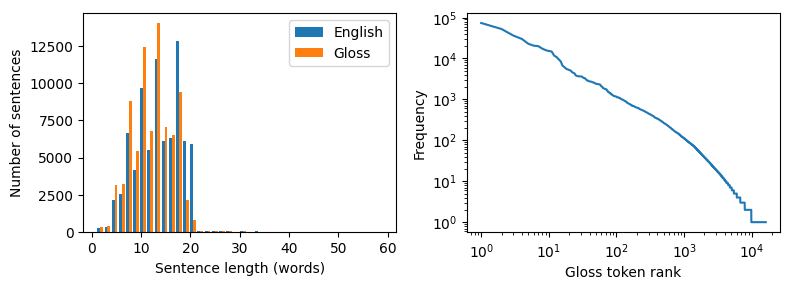

In [ ]:
!pip -q install datasets pandas matplotlib

import re, collections, pandas as pd, matplotlib.pyplot as plt
from datasets import load_dataset

df = load_dataset("achrafothman/aslg_pc12", split="train").to_pandas()
raw_n = len(df)

# 1) Normalization
clean = lambda s: re.sub(r"\s+", " ", s.replace("\ufeff", "")).strip()
df["text"] = df["text"].map(clean); df["gloss"] = df["gloss"].map(clean)

# 2) Filtering (empty / single-character)
df = df[(df.text.str.len() > 1) & (df.gloss.str.len() > 1)]
after_filter = len(df)

# 3) Deduplication
dups = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

# 4) Length stats
df["n_text"] = df.text.str.split().str.len()
df["n_gloss"] = df.gloss.str.split().str.len()
print(f"raw={raw_n} | after_filter={after_filter} | dup_removed={dups} | clean={len(df)}")

for name, col in [("English", "text"), ("Gloss", "gloss")]:
    toks = [w for s in df[col] for w in s.split()]
    n = df["n_" + ("text" if col == "text" else "gloss")]
    print(f"{name}: avg={n.mean():.2f} median={n.median():.0f} max={n.max()} "
          f"p95={n.quantile(.95):.0f} vocab={len(set(toks))} "
          f"TTR={len(set(toks))/len(toks):.4f} tokens={len(toks)}")

print("avg gloss/text length ratio:", (df.n_gloss / df.n_text).mean().round(3))
g = [w for s in df.gloss for w in s.split()]
print("DESC-/X- share of gloss tokens:",
      round(sum(w.startswith(("DESC-", "X-")) for w in g) / len(g) * 100, 2), "%")
print("sentences with <=5 words (formulaic):", round((df.n_text <= 5).mean()*100, 1), "%")

# 5) Split 80/10/10 (seed 42) after dedup
tr = df.sample(frac=0.8, random_state=42); rest = df.drop(tr.index)
va = rest.sample(frac=0.5, random_state=42); te = rest.drop(va.index)
print("split:", len(tr), len(va), len(te))

# 6) Figures
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].hist([df.n_text, df.n_gloss], bins=40, label=["English", "Gloss"]); ax[0].legend()
ax[0].set_xlabel("Sentence length (words)"); ax[0].set_ylabel("Number of sentences")
freq = sorted(collections.Counter(g).values(), reverse=True)
ax[1].loglog(range(1, len(freq)+1), freq)
ax[1].set_xlabel("Gloss token rank"); ax[1].set_ylabel("Frequency")
plt.tight_layout(); plt.savefig("eda.pdf")

## 1.3 EDA figure (Figure 1 in the report)

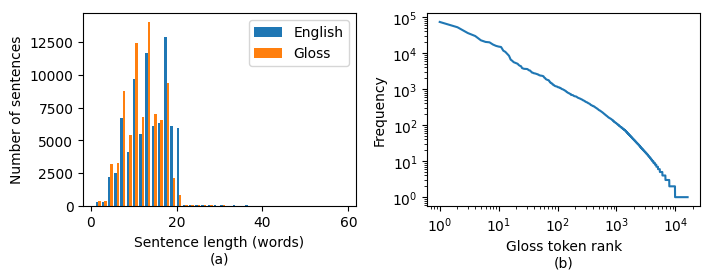

In [ ]:
import collections
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 10})
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.9))

ax[0].hist([df.n_text, df.n_gloss], bins=40, label=["English", "Gloss"])
ax[0].legend()
ax[0].set_xlabel("Sentence length (words)\n(a)")
ax[0].set_ylabel("Number of sentences")

freq = sorted(collections.Counter(g).values(), reverse=True)
ax[1].loglog(range(1, len(freq) + 1), freq)
ax[1].set_xlabel("Gloss token rank\n(b)")
ax[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("eda.pdf", bbox_inches="tight")

## 1.4 Save the splits to the shared folder
*Added for Phase 2.* This saves the `tr`, `va` and `te` splits created above, so every later part uses exactly the same data.

In [ ]:
for name, part in [("train", tr), ("val", va), ("test", te)]:
    part[["text", "gloss"]].to_csv(f"{CFG['data_dir']}/{name}.csv", index=False)

if os.path.exists("eda.pdf"):
    import shutil
    shutil.copy("eda.pdf", f"{CFG['figures_dir']}/eda.pdf")

train_df, val_df, test_df = load_splits()
print("Saved and reloaded:", len(train_df), len(val_df), len(test_df))  # expected: 64871 8109 8109

Saved and reloaded: 64871 8109 8109


---
# Part 2: Step 1: Base model and zero-shot baseline
**Owner:** Member 1 Lena · **Report:** Methodology (base model) and Experimental Setup
**Output:** `outputs/preds_zero_shot.csv` (this is the "before" result for the comparison)

## 2.1 Load the pre-trained base model and tokenizer

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

tokenizer = AutoTokenizer.from_pretrained(CFG["model_name"])
base_model = AutoModelForSeq2SeqLM.from_pretrained(CFG["model_name"]).to(DEVICE)
base_model.eval()

# Parameter counts (for the report and the LoRA comparison in Part 4)
n_total = sum(p.numel() for p in base_model.parameters())
n_trainable = sum(p.numel() for p in base_model.parameters() if p.requires_grad)

print("Model:", CFG["model_name"])
print(f"Total parameters:     {n_total:,} (~{n_total / 1e6:.1f}M)")
print(f"Trainable parameters: {n_trainable:,} ({n_trainable / n_total * 100:.1f}%)")
print("Vocabulary size:", tokenizer.vocab_size, "| model dimension:", base_model.config.d_model)
print("Encoder layers:", base_model.config.num_layers,
      "| decoder layers:", base_model.config.num_decoder_layers,
      "| attention heads:", base_model.config.num_heads)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Model: google/flan-t5-base
Total parameters:     247,577,856 (~247.6M)
Trainable parameters: 247,577,856 (100.0%)
Vocabulary size: 32100 | model dimension: 768
Encoder layers: 12 | decoder layers: 12 | attention heads: 12


## 2.2 Zero-shot predictions on the test set

In [ ]:
train_df, val_df, test_df = load_splits()
print("Test set size:", len(test_df))  # expected: 8109

start = time.time()
preds = translate(base_model, tokenizer, test_df["text"].tolist())
print(f"Zero-shot generation time: {(time.time() - start) / 60:.1f} min")

zero_shot_df = save_preds("zero_shot", test_df, preds)

# Show 5 examples to check the output looks sensible
pd.set_option("display.max_colwidth", None)
for _, row in zero_shot_df.sample(5, random_state=CFG["seed"]).iterrows():
    print("Input:     ", row["text"])
    print("Reference: ", row["reference"])
    print("Zero-shot: ", row["prediction"])
    print("-" * 80)

Test set size: 8109


Generating:   0%|          | 0/254 [00:00<?, ?it/s]

Zero-shot generation time: 28.5 min
Saved 8109 predictions to /content/drive/MyDrive/NLP_Project/outputs/preds_zero_shot.csv
Input:      can we trust the commission ?
Reference:  CAN X-WE TRUST COMMISSION ?
Zero-shot:  can we trust the commission ?
--------------------------------------------------------------------------------
Input:      pt regional disparities remain a challenge in the context of the european union .
Reference:  PT DESC-REGIONAL DISPARITY REMAIN CHALLENGE IN CONTEXT EUROPEAN UNION .
Zero-shot:  pt regional disparities remain a challenge in the context of the european union .
--------------------------------------------------------------------------------
Input:      our duty is to encourage regional integration and to oppose any signed agreement that would weaken such integration .
Reference:  X-WE DUTY BE TO ENCOURAGE DESC-REGIONAL INTEGRATION AND TO OPPOSE ANY SIGN AGREEMENT THAT WOULD WEAKEN DESC-SUCH INTEGRATION .
Zero-shot:  our duty is to encourage regional in

---
# Part 3: Step 2a: Full fine-tuning
**Owner:** Member 2 Natali · **Report:** Methodology (post-training) and training details (Section 4.4)
**Output:** checkpoints in `checkpoints/full_ft`, final model in `models/`, and `outputs/preds_full_ft.csv`

## 3.1 Tokenize the train and validation splits

In [ ]:
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

train_df, val_df, test_df = load_splits()

# Part 3 loads its own fresh copy of the base model, so Part 2's base_model stays untouched for Part 4 (LoRA).
tokenizer = AutoTokenizer.from_pretrained(CFG["model_name"])
model = AutoModelForSeq2SeqLM.from_pretrained(CFG["model_name"]).to(DEVICE)


def preprocess(batch):
    inputs = [CFG["prefix"] + t for t in batch["text"]]
    return tokenizer(inputs, text_target=batch["gloss"], max_length=CFG["max_len"], truncation=True)


train_ds = Dataset.from_pandas(train_df, preserve_index=False).map(
    preprocess, batched=True, remove_columns=["text", "gloss"], desc="Tokenizing train")
val_ds = Dataset.from_pandas(val_df, preserve_index=False).map(
    preprocess, batched=True, remove_columns=["text", "gloss"], desc="Tokenizing val")
print(train_ds)
print(val_ds)

# Checks for the report: truncation and unknown tokens in the gloss targets
n_trunc = sum(len(x) >= CFG["max_len"] for x in train_ds["input_ids"])
label_lens = [len(x) for x in train_ds["labels"]]
unk_id = tokenizer.unk_token_id
n_unk = sum(tok == unk_id for x in train_ds["labels"] for tok in x)
print(f"Inputs truncated at {CFG['max_len']} tokens: {n_trunc}")
print(f"Gloss length in subword tokens: mean={np.mean(label_lens):.1f}, max={max(label_lens)}")
print(f"Unknown tokens in gloss targets: {n_unk} ({n_unk / sum(label_lens) * 100:.3f}%)")

# One example decoded back, to confirm the prefix and target look right
print("Input :", tokenizer.decode(train_ds[0]["input_ids"], skip_special_tokens=True))
print("Target:", tokenizer.decode(train_ds[0]["labels"], skip_special_tokens=True))

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Tokenizing train:   0%|          | 0/64871 [00:00<?, ? examples/s]

Tokenizing val:   0%|          | 0/8109 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 64871
})
Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 8109
})
Inputs truncated at 128 tokens: 0
Gloss length in subword tokens: mean=35.6, max=128
Unknown tokens in gloss targets: 66 (0.003%)
Input : translate English to ASL gloss: they need us and we need them .
Target: X-Y NEED X-WE AND X-WE NEED X-Y .


## 3.2 Training arguments

In [ ]:
import math
from transformers import Seq2SeqTrainingArguments, DataCollatorForSeq2Seq

# Warmup is given as a number of steps (works on every transformers version)
steps_per_epoch = math.ceil(len(train_ds) / (CFG["train_batch_size"] * CFG["grad_accum_steps"]))
total_steps = steps_per_epoch * CFG["num_epochs"]
warmup_steps = int(CFG["warmup_ratio"] * total_steps)
print(f"Optimizer steps: {steps_per_epoch} per epoch, {total_steps} in total, {warmup_steps} warmup")

training_args = Seq2SeqTrainingArguments(
    output_dir=CFG["ckpt_full"],
    learning_rate=CFG["learning_rate"],
    per_device_train_batch_size=CFG["train_batch_size"],
    per_device_eval_batch_size=CFG["eval_batch_size"],
    gradient_accumulation_steps=CFG["grad_accum_steps"],
    num_train_epochs=CFG["num_epochs"],
    weight_decay=CFG["weight_decay"],
    warmup_steps=warmup_steps,
    lr_scheduler_type=CFG["lr_scheduler"],
    fp16=CFG["fp16"],
    # validation loss every save_steps; the checkpoint with the lowest validation loss is kept as the final model
    eval_strategy="steps",
    eval_steps=CFG["save_steps"],
    save_strategy="steps",
    save_steps=CFG["save_steps"],
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_steps=100,
    seed=CFG["seed"],
    report_to="none",
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)  # pads per batch; label padding is -100 (ignored by the loss)

Optimizer steps: 2028 per epoch, 6084 in total, 608 warmup


## 3.3 Train (with resume support)
As in the reference project, set `CFG["resume"] = True` to continue after a disconnected session.

In [ ]:
from transformers import Seq2SeqTrainer

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    processing_class=tokenizer,
)

resume = (CFG["resume_checkpoint"] or True) if CFG["resume"] else None
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()

start = time.time()
train_result = trainer.train(resume_from_checkpoint=resume)
session_min = (time.time() - start) / 60

# Numbers for the report (Section 4.4) and for the efficiency table in Part 4.
# If the run was resumed, the time of each session is added up.
stats_path = f"{CFG['outputs_dir']}/full_ft_stats.json"
stats = json.load(open(stats_path)) if (CFG["resume"] and os.path.exists(stats_path)) else {}
stats["session_minutes"] = stats.get("session_minutes", []) + [round(session_min, 1)]
stats["train_time_min"] = round(sum(stats["session_minutes"]), 1)
peak_gb = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else 0.0
stats["peak_gpu_mem_gb"] = round(max(peak_gb, stats.get("peak_gpu_mem_gb", 0.0)), 2)
stats["trainable_params"] = sum(p.numel() for p in model.parameters() if p.requires_grad)
stats["total_params"] = sum(p.numel() for p in model.parameters())
stats["global_steps"] = trainer.state.global_step
stats["best_checkpoint"] = trainer.state.best_model_checkpoint

logs = trainer.state.log_history
train_losses = [h["loss"] for h in logs if "loss" in h]
stats["final_train_loss"] = round(train_losses[-1] if train_losses else train_result.training_loss, 4)
stats["best_val_loss"] = round(trainer.state.best_metric, 4) if trainer.state.best_metric is not None else None

json.dump(stats, open(stats_path, "w"), indent=2)
json.dump(logs, open(f"{CFG['outputs_dir']}/full_ft_log_history.json", "w"), indent=2)
print(json.dumps(stats, indent=2))

# Save the best model straight away, so it is safe even if the session disconnects before 3.4
trainer.save_model(CFG["model_full"])
tokenizer.save_pretrained(CFG["model_full"])
print("Saved the fine-tuned model to", CFG["model_full"])

Step,Training Loss,Validation Loss
1000,1.898117,0.228339


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Step,Training Loss,Validation Loss
1000,1.898117,0.228339
2000,1.211689,0.139267
3000,0.931946,0.109448


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 3.4 Save the model and the test predictions

In [ ]:
import matplotlib.pyplot as plt

# The model was saved at the end of 3.3. If the session restarted since then, reload it instead of retraining.
if "trainer" in globals():
    model = trainer.model  # best checkpoint (lowest validation loss)
    logs = trainer.state.log_history
else:
    tokenizer = AutoTokenizer.from_pretrained(CFG["model_full"])
    model = AutoModelForSeq2SeqLM.from_pretrained(CFG["model_full"]).to(DEVICE)
    logs = json.load(open(f"{CFG['outputs_dir']}/full_ft_log_history.json"))
    print("Loaded the fine-tuned model from", CFG["model_full"])

# Test predictions with the shared decoding settings
train_df, val_df, test_df = load_splits()
start = time.time()
preds = translate(model, tokenizer, test_df["text"].tolist())
print(f"Full fine-tuning generation time: {(time.time() - start) / 60:.1f} min")
full_ft_df = save_preds("full_ft", test_df, preds)

# Same 5 sentences as Part 2, so the before/after can be compared directly
zs_path = CFG["preds"]["zero_shot"]
zs = pd.read_csv(zs_path, keep_default_na=False) if os.path.exists(zs_path) else None
pd.set_option("display.max_colwidth", None)
for i, row in full_ft_df.sample(5, random_state=CFG["seed"]).iterrows():
    print("Input:     ", row["text"])
    print("Reference: ", row["reference"])
    if zs is not None:
        print("Zero-shot: ", zs.loc[i, "prediction"])
    print("Full FT:   ", row["prediction"])
    print("-" * 80)

# Training and validation loss curves (figure for the report and slides)
train_pts = [(h["step"], h["loss"]) for h in logs if "loss" in h]
val_pts = [(h["step"], h["eval_loss"]) for h in logs if "eval_loss" in h]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(*zip(*train_pts), label="Training loss")
if val_pts:
    ax.plot(*zip(*val_pts), marker="o", label="Validation loss")
ax.set_xlabel("Optimizer step")
ax.set_ylabel("Cross-entropy loss")
ax.legend()
plt.tight_layout()
plt.savefig(f"{CFG['figures_dir']}/loss_full_ft.pdf", bbox_inches="tight")
plt.savefig(f"{CFG['figures_dir']}/loss_full_ft.png", dpi=200, bbox_inches="tight")
plt.show()

---
# Part 4: Step 2b: LoRA fine-tuning (PEFT)
**Owner:** Member 3 Alhanouf · **Report:** LoRA subsection and efficiency comparison with full fine-tuning
**Output:** checkpoints in `checkpoints/lora`, adapter in `models/`, and `outputs/preds_lora.csv`
Use the same splits, tokenization and decoding as Part 3. Only the adaptation method changes.


## 4.1 Wrap the base model with LoRA
**4.1a** tokenizes the data exactly as Part 3 does (same prefix, same `max_len`, same tokenizer), so the two methods see identical inputs.
**4.1b** loads a *fresh* copy of FLAN-T5-base and attaches the LoRA adapters. `get_peft_model` modifies the model it receives in place, so a fresh copy keeps Part 2's `base_model` clean.


In [ ]:
# 4.1a Tokenize the train and validation splits (identical to Part 3.1)
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

train_df, val_df, test_df = load_splits()
lora_tokenizer = AutoTokenizer.from_pretrained(CFG["model_name"])


def lora_preprocess(batch):
    inputs = [CFG["prefix"] + t for t in batch["text"]]
    return lora_tokenizer(inputs, text_target=batch["gloss"], max_length=CFG["max_len"], truncation=True)


lora_train_ds = Dataset.from_pandas(train_df, preserve_index=False).map(
    lora_preprocess, batched=True, remove_columns=["text", "gloss"], desc="Tokenizing train")
lora_val_ds = Dataset.from_pandas(val_df, preserve_index=False).map(
    lora_preprocess, batched=True, remove_columns=["text", "gloss"], desc="Tokenizing val")
print(lora_train_ds)
print(lora_val_ds)
print("Expected sizes: 64871 train / 8109 validation (same as Part 3)")

# One example decoded back, to confirm the prefix and target look right
print("Input :", lora_tokenizer.decode(lora_train_ds[0]["input_ids"], skip_special_tokens=True))
print("Target:", lora_tokenizer.decode(lora_train_ds[0]["labels"], skip_special_tokens=True))

In [ ]:
!pip -q uninstall -y torchao

In [ ]:
# 4.1b Load a fresh base model and attach the LoRA adapters
from peft import LoraConfig, get_peft_model, TaskType

transformers.set_seed(CFG["seed"])   # the LoRA A matrices are randomly initialised, so fix the seed first
lora_base = AutoModelForSeq2SeqLM.from_pretrained(CFG["model_name"]).to(DEVICE)

lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=CFG["lora_r"],
    lora_alpha=CFG["lora_alpha"],
    lora_dropout=CFG["lora_dropout"],
    target_modules=CFG["lora_target_modules"],
    bias="none",
)
lora_model = get_peft_model(lora_base, lora_config)
lora_model.print_trainable_parameters()

# Counts for the report (Section 4.4) and for the efficiency table in 4.4
lora_n_trainable = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)
lora_n_total = sum(p.numel() for p in lora_model.parameters())
lora_n_modules = sum(1 for n, _ in lora_model.named_modules() if n.endswith(".lora_A"))
print(f"Trainable parameters: {lora_n_trainable:,} ({lora_n_trainable / lora_n_total * 100:.3f}% of {lora_n_total:,})")
print(f"Attention projections with a LoRA adapter: {lora_n_modules}")

# Sanity checks: only LoRA weights train, and the adapters sit where we expect
assert all("lora_" in n for n, p in lora_model.named_parameters() if p.requires_grad), "a non-LoRA weight is trainable"
print("Check passed: every trainable parameter is a LoRA weight; the base model is frozen.")
print("Expected for r=16 on q and v: 72 adapters (12 encoder self-attn + 12 decoder self-attn + 12 decoder cross-attn, x2 for q and v)")
print("                              72 x 16 x (768 + 768) = 1,769,472 trainable parameters")

## 4.2 Train
Same recipe as Part 3 (3 epochs, effective batch size 32, linear schedule with 10% warmup, weight decay 0.01, fp32, seed 42, validation loss every 1000 steps, best checkpoint kept).
The only changes are `output_dir` and the learning rate (`lora_learning_rate = 1e-3` instead of `3e-5`), plus `label_names=["labels"]`, which the Trainer needs to compute the validation loss for a PEFT model.

In [ ]:
# 4.2a Training arguments
import math
from transformers import Seq2SeqTrainingArguments, DataCollatorForSeq2Seq, Seq2SeqTrainer

# Extra LoRA-only settings (defaults here, so Part 0 does not have to change)
CFG.setdefault("lora_resume", False)             # True = continue an interrupted LoRA run
CFG.setdefault("lora_resume_checkpoint", None)   # e.g. ".../checkpoints/lora/checkpoint-3000"; None = latest
CFG.setdefault("lora_max_steps", -1)             # -1 = full run. Set to 20 for the smoke test.
LORA_SMOKE = CFG["lora_max_steps"] > 0
if LORA_SMOKE:
    print(">>> SMOKE TEST MODE: only", CFG["lora_max_steps"], "steps; nothing will be saved to the shared folder <<<")

steps_per_epoch = math.ceil(len(lora_train_ds) / (CFG["train_batch_size"] * CFG["grad_accum_steps"]))
total_steps = steps_per_epoch * CFG["num_epochs"]
warmup_steps = int(CFG["warmup_ratio"] * total_steps)
print(f"Optimizer steps: {steps_per_epoch} per epoch, {total_steps} in total, {warmup_steps} warmup")

every = CFG["lora_max_steps"] if LORA_SMOKE else CFG["save_steps"]   # evaluate and save every `every` steps

lora_args = Seq2SeqTrainingArguments(
    output_dir="/tmp/lora_smoke" if LORA_SMOKE else CFG["ckpt_lora"],
    learning_rate=CFG["lora_learning_rate"],
    per_device_train_batch_size=CFG["train_batch_size"],
    per_device_eval_batch_size=CFG["eval_batch_size"],
    gradient_accumulation_steps=CFG["grad_accum_steps"],
    num_train_epochs=CFG["num_epochs"],
    max_steps=CFG["lora_max_steps"],
    weight_decay=CFG["weight_decay"],
    warmup_steps=warmup_steps,
    lr_scheduler_type=CFG["lr_scheduler"],
    fp16=CFG["fp16"],
    eval_strategy="steps",
    eval_steps=every,
    save_strategy="steps",
    save_steps=every,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_steps=5 if LORA_SMOKE else 100,
    label_names=["labels"],     # needed so the Trainer computes eval_loss for a PEFT-wrapped model
    seed=CFG["seed"],
    report_to="none",
)

lora_collator = DataCollatorForSeq2Seq(lora_tokenizer, model=lora_model)   # pads per batch; label padding is -100

In [ ]:
# 4.2b Train (with resume support), then record the numbers for the report
lora_trainer = Seq2SeqTrainer(
    model=lora_model,
    args=lora_args,
    train_dataset=lora_train_ds,
    eval_dataset=lora_val_ds,
    data_collator=lora_collator,
    processing_class=lora_tokenizer,
)

resume = (CFG["lora_resume_checkpoint"] or True) if CFG["lora_resume"] else None
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()

start = time.time()
lora_result = lora_trainer.train(resume_from_checkpoint=resume)
session_min = (time.time() - start) / 60

# Same fields as full_ft_stats.json, so the efficiency table in 4.4 compares like with like.
# If the run was resumed, the time of each session is added up.
stats_path = f"{CFG['outputs_dir']}/lora_stats.json"
lora_stats = json.load(open(stats_path)) if (CFG["lora_resume"] and os.path.exists(stats_path)) else {}
lora_stats["session_minutes"] = lora_stats.get("session_minutes", []) + [round(session_min, 1)]
lora_stats["train_time_min"] = round(sum(lora_stats["session_minutes"]), 1)
peak_gb = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else 0.0
lora_stats["peak_gpu_mem_gb"] = round(max(peak_gb, lora_stats.get("peak_gpu_mem_gb", 0.0)), 2)
lora_stats["trainable_params"] = lora_n_trainable
lora_stats["total_params"] = lora_n_total
lora_stats["trainable_pct"] = round(lora_n_trainable / lora_n_total * 100, 3)
lora_stats["global_steps"] = lora_trainer.state.global_step
lora_stats["best_checkpoint"] = lora_trainer.state.best_model_checkpoint

lora_logs = lora_trainer.state.log_history
train_losses = [h["loss"] for h in lora_logs if "loss" in h]
val_losses = [h["eval_loss"] for h in lora_logs if "eval_loss" in h]
lora_stats["final_train_loss"] = round(train_losses[-1] if train_losses else lora_result.training_loss, 4)
lora_stats["final_val_loss"] = round(val_losses[-1], 4) if val_losses else None
lora_stats["best_val_loss"] = round(lora_trainer.state.best_metric, 4) if lora_trainer.state.best_metric is not None else None
lora_stats["hyperparameters"] = {
    "r": CFG["lora_r"], "alpha": CFG["lora_alpha"], "dropout": CFG["lora_dropout"],
    "target_modules": CFG["lora_target_modules"], "learning_rate": CFG["lora_learning_rate"],
    "epochs": CFG["num_epochs"], "effective_batch_size": CFG["train_batch_size"] * CFG["grad_accum_steps"],
}
print(json.dumps(lora_stats, indent=2))

if LORA_SMOKE:
    print("\nSMOKE TEST: training, validation and best-model loading all ran. Nothing was saved.")
    print("Now set CFG['lora_max_steps'] = -1, restart the runtime, and run Parts 0 to 1.4 and Part 4 again.")
else:
    json.dump(lora_stats, open(stats_path, "w"), indent=2)
    json.dump(lora_logs, open(f"{CFG['outputs_dir']}/lora_log_history.json", "w"), indent=2)
    # Save the best adapter straight away, so it is safe even if the session disconnects before 4.3.
    # For a PEFT model this writes only the adapter (adapter_model.safetensors + adapter_config.json), not the whole model.
    lora_trainer.save_model(CFG["model_lora"])
    lora_tokenizer.save_pretrained(CFG["model_lora"])
    print("Saved the LoRA adapter to", CFG["model_lora"])

## 4.3 Save the adapter and the test predictions
The adapter was already saved at the end of 4.2b. This cell generates the test predictions with the **shared `translate()` function** (same beam search settings as every other model),
shows the same 5 sentences as Parts 2 and 3 so the three models can be compared directly, and saves the loss-curve figure.
If the session restarted after training, the cell reloads the base model and attaches the saved adapter instead of retraining.

In [ ]:
import matplotlib.pyplot as plt
from peft import PeftModel

if "lora_trainer" in globals():
    lora_model = lora_trainer.model            # best checkpoint (lowest validation loss)
    lora_logs = lora_trainer.state.log_history
else:
    lora_tokenizer = AutoTokenizer.from_pretrained(CFG["model_lora"])
    lora_base = AutoModelForSeq2SeqLM.from_pretrained(CFG["model_name"]).to(DEVICE)
    lora_model = PeftModel.from_pretrained(lora_base, CFG["model_lora"]).to(DEVICE)
    lora_logs = json.load(open(f"{CFG['outputs_dir']}/lora_log_history.json"))
    print("Loaded the base model and the LoRA adapter from", CFG["model_lora"])

train_df, val_df, test_df = load_splits()

if CFG.get("lora_max_steps", -1) > 0:   # smoke-test mode (see 4.2a)
    # Smoke test: only a handful of sentences, nothing saved
    quick = test_df.head(8)
    quick_preds = translate(lora_model, lora_tokenizer, quick["text"].tolist())
    for t, r, p in zip(quick["text"], quick["gloss"], quick_preds):
        print("Input:     ", t); print("Reference: ", r); print("LoRA:      ", p); print("-" * 80)
    print("SMOKE TEST: generation works. (After only 20 steps the output quality is not meaningful.)")
else:
    start = time.time()
    preds = translate(lora_model, lora_tokenizer, test_df["text"].tolist())
    gen_min = (time.time() - start) / 60
    print(f"LoRA generation time: {gen_min:.1f} min")
    lora_df = save_preds("lora", test_df, preds)

    # Record generation time and adapter size next to the training stats
    stats_path = f"{CFG['outputs_dir']}/lora_stats.json"
    lora_stats = json.load(open(stats_path))
    lora_stats["generation_min"] = round(gen_min, 1)
    lora_stats["adapter_size_mb"] = round(sum(
        os.path.getsize(os.path.join(CFG["model_lora"], f)) for f in os.listdir(CFG["model_lora"])
        if f.startswith("adapter_")) / 1e6, 2)
    json.dump(lora_stats, open(stats_path, "w"), indent=2)
    print("Adapter size on disk:", lora_stats["adapter_size_mb"], "MB")

    # Same 5 sentences as Parts 2 and 3 (same random_state), so zero-shot / full FT / LoRA line up
    def _load(name):
        p = CFG["preds"][name]
        return pd.read_csv(p, keep_default_na=False) if os.path.exists(p) else None
    zs, ft = _load("zero_shot"), _load("full_ft")
    for i, row in lora_df.sample(5, random_state=CFG["seed"]).iterrows():
        print("Input:     ", row["text"])
        print("Reference: ", row["reference"])
        if zs is not None: print("Zero-shot: ", zs.loc[i, "prediction"])
        if ft is not None: print("Full FT:   ", ft.loc[i, "prediction"])
        print("LoRA:      ", row["prediction"])
        print("-" * 80)

    # Training and validation loss curves (figure for the report and slides)
    train_pts = [(h["step"], h["loss"]) for h in lora_logs if "loss" in h]
    val_pts = [(h["step"], h["eval_loss"]) for h in lora_logs if "eval_loss" in h]
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(*zip(*train_pts), label="Training loss")
    if val_pts:
        ax.plot(*zip(*val_pts), marker="o", label="Validation loss")
    ax.set_xlabel("Optimizer step")
    ax.set_ylabel("Cross-entropy loss")
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"{CFG['figures_dir']}/loss_lora.pdf", bbox_inches="tight")
    plt.savefig(f"{CFG['figures_dir']}/loss_lora.png", dpi=200, bbox_inches="tight")
    plt.show()

## 4.4 Efficiency comparison
Builds the table *method | trainable parameters | % of total | training time | peak GPU memory* (plus best validation loss and the size of what has to be saved),
using the numbers recorded by Part 3 (`full_ft_stats.json`) and by 4.2b (`lora_stats.json`). It also overlays the two validation-loss curves.


In [ ]:
def _dir_mb(path):
    return round(sum(os.path.getsize(os.path.join(path, f)) for f in os.listdir(path)
                     if os.path.isfile(os.path.join(path, f)) and not f.startswith(".")) / 1e6, 1)

full_path = f"{CFG['outputs_dir']}/full_ft_stats.json"
lora_path = f"{CFG['outputs_dir']}/lora_stats.json"
full_s = json.load(open(full_path)) if os.path.exists(full_path) else None
lora_s = json.load(open(lora_path)) if os.path.exists(lora_path) else None
if full_s is None:
    print("full_ft_stats.json not found: run Part 3 first to fill the full fine-tuning row.")

rows = []
if full_s:
    rows.append({
        "Method": "Full fine-tuning",
        "Trainable params": full_s["trainable_params"],
        "% of total": round(full_s["trainable_params"] / full_s["total_params"] * 100, 2),
        "Training time (min)": full_s["train_time_min"],
        "Peak GPU memory (GB)": full_s["peak_gpu_mem_gb"],
        "Best val loss": full_s["best_val_loss"],
        "Saved size (MB)": _dir_mb(CFG["model_full"]) if os.path.isdir(CFG["model_full"]) else None,
    })
if lora_s:
    rows.append({
        "Method": f"LoRA (r={CFG['lora_r']}, {'+'.join(CFG['lora_target_modules'])})",
        "Trainable params": lora_s["trainable_params"],
        "% of total": round(lora_s["trainable_params"] / lora_s["total_params"] * 100, 2),
        "Training time (min)": lora_s["train_time_min"],
        "Peak GPU memory (GB)": lora_s["peak_gpu_mem_gb"],
        "Best val loss": lora_s["best_val_loss"],
        "Saved size (MB)": _dir_mb(CFG["model_lora"]) if os.path.isdir(CFG["model_lora"]) else None,
    })

eff = pd.DataFrame(rows)
pd.set_option("display.width", 200)
display(eff)
eff.to_csv(f"{CFG['outputs_dir']}/efficiency_comparison.csv", index=False)
print("Saved", f"{CFG['outputs_dir']}/efficiency_comparison.csv")

if full_s and lora_s:
    print(f"LoRA trains {lora_s['trainable_params'] / full_s['trainable_params'] * 100:.2f}% of the parameters of full fine-tuning,")
    print(f"takes {lora_s['train_time_min'] / full_s['train_time_min'] * 100:.0f}% of the training time and "
          f"{lora_s['peak_gpu_mem_gb'] / full_s['peak_gpu_mem_gb'] * 100:.0f}% of the peak GPU memory.")

# Validation-loss curves of both methods on one plot (figure for the report and slides)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.2))
for label, fname in [("Full fine-tuning", "full_ft_log_history.json"), (f"LoRA (r={CFG['lora_r']})", "lora_log_history.json")]:
    p = f"{CFG['outputs_dir']}/{fname}"
    if os.path.exists(p):
        pts = [(h["step"], h["eval_loss"]) for h in json.load(open(p)) if "eval_loss" in h]
        if pts:
            ax.plot(*zip(*pts), marker="o", label=label)
ax.set_xlabel("Optimizer step"); ax.set_ylabel("Validation loss"); ax.legend()
plt.tight_layout()
plt.savefig(f"{CFG['figures_dir']}/val_loss_full_vs_lora.pdf", bbox_inches="tight")
plt.savefig(f"{CFG['figures_dir']}/val_loss_full_vs_lora.png", dpi=200, bbox_inches="tight")
plt.show()

---
# Part 5: Step 3: Comparative evaluation (pre vs. post)
**Owner:** Member 4 *(name)* · **Report:** Results and Discussion
**Input:** the three prediction files in `outputs/` · **Output:** results table and error analysis
The scoring code can be written and tested on `preds_zero_shot.csv` while the training runs.

## 5.1 Metrics: corpus-level BLEU and ROUGE-L

In [ ]:
# import evaluate; bleu = evaluate.load("sacrebleu"); rouge = evaluate.load("rouge")
# For each name in CFG["preds"] that exists: read the CSV (keep_default_na=False) and compute
#   BLEU (references as [[ref], ...]) and ROUGE-L against the reference gloss.

## 5.2 Results table

In [ ]:
# Table: model | BLEU | ROUGE-L, rows: zero-shot, full fine-tuning, LoRA.
# Add the BART-base BLEU of 76.7 from the literature as a reference row (different test sample, see Section 4.5).
# Save it to CFG["outputs_dir"] and make a bar chart for the slides in CFG["figures_dir"].

## 5.3 Error analysis

In [ ]:
# Group the errors of the fine-tuned model(s) by type (Section 4.5):
#   word-order errors, dropped tokens, missing or incorrect DESC- / X- markers.
# Count each type on the test set and show 2 examples per type.

---
# Part 6: Sample output scenarios and demo
**Owner:** Member 1 *(name)* · **Report:** Sample outputs section (required by the project description)
Run this part after Parts 3 and 4 are finished.

## 6.1 Sample output scenarios

In [ ]:
# Choose a fixed set of about 10 test sentences (short, long, with DESC-/X- markers, and a few everyday sentences
# outside the corpus domain). Show: English input | reference gloss | zero-shot | full fine-tuning | LoRA.
# Save the table to CFG["outputs_dir"] for the report and slides.

## 6.2 Interactive demo

In [ ]:
# Signing figure: setup (run once per session)
# The gloss-to-pose method is adapted from the SignBridge server (github.com/SignBridgeApp/server, MIT licence).
# Each dictionary word is a pre-recorded MediaPipe skeleton (.pose file); clips are trimmed, joined and smoothed.
!pip -q install pose-format num2words

import os, re, zipfile, subprocess
import numpy as np
import scipy.signal
from scipy.spatial.distance import cdist
from num2words import num2words
from pose_format import Pose
from pose_format.numpy import NumPyPoseBody
from pose_format.pose_visualizer import PoseVisualizer
from pose_format.utils.generic import reduce_holistic, correct_wrists, pose_normalization_info
from IPython.display import Image, display

# The 280 MB dictionary is downloaded to Drive once, then unzipped to the fast local disk each session
SIGN_ZIP = f"{PROJECT_DIR}/signbridge_gloss2pose.zip"
SIGN_DIR = "/content/gloss2pose" if IN_COLAB else os.path.abspath("gloss2pose")
if not os.path.exists(SIGN_ZIP):
    subprocess.run(["wget", "-q", "-O", SIGN_ZIP,
                    "https://github.com/SignBridgeApp/models/releases/download/v0.0/gloss2pose.zip"], check=True)
if not os.path.exists(f"{SIGN_DIR}/words.txt"):
    with zipfile.ZipFile(SIGN_ZIP) as z:
        z.extractall(os.path.dirname(SIGN_DIR))

with open(f"{SIGN_DIR}/words.txt", encoding="utf-8") as f:
    SIGN_WORDS = {w.strip() for w in f if w.strip()}
MAX_PHRASE = max(len(w.split()) for w in SIGN_WORDS)   # some entries are phrases, e.g. "thank you"
print(f"Sign dictionary: {len(SIGN_WORDS)} entries")


def clean_gloss(gloss):
    """ASLG gloss -> lowercase words the dictionary can match (drops X-/DESC- markers and punctuation)."""
    words = re.findall(r"[a-z0-9']+", re.sub(r"\b(?:X|DESC)-", "", gloss).lower())
    out = []
    for w in words:
        out.extend(num2words(int(w)).replace("-", " ").split() if w.isdigit() else [w])
    return out


def plan_signs(words):
    """Match the longest dictionary phrase first; otherwise fingerspell. Returns (tokens, report)."""
    tokens, report, i = [], [], 0
    while i < len(words):
        for n in range(min(MAX_PHRASE, len(words) - i), 0, -1):
            phrase = " ".join(words[i:i + n])
            if phrase in SIGN_WORDS:
                tokens.append(phrase); report.append((phrase, "sign")); i += n
                break
        else:
            letters = [c for c in words[i] if c in SIGN_WORDS]
            missing = sorted({c for c in words[i] if c not in SIGN_WORDS})
            tokens.extend(letters)
            report.append((words[i], "fingerspelled" + (f" (no clip for: {', '.join(missing)})" if missing else "")))
            i += 1
    return tokens, report


def _read_pose(token):
    with open(f"{SIGN_DIR}/asl/{token}.pose", "rb") as f:
        return Pose.read(f.read())


def _trim(pose, start, end):
    """Keep only the frames where a hand is visible."""
    h = pose.header
    wrists = [h._get_point_index("LEFT_HAND_LANDMARKS", "WRIST"), h._get_point_index("RIGHT_HAND_LANDMARKS", "WRIST")]
    hands = pose.body.confidence[:, 0, wrists].sum(axis=1) > 0
    if not hands.any():
        return pose
    a = int(np.argmax(hands)) if start else 0
    b = len(hands) - int(np.argmax(hands[::-1])) if end else len(hands)
    pose.body = pose.body[a:b]
    return pose


def _best_join(p1, p2, window=0.3):
    """Frames where the end of one clip is closest to the start of the next."""
    n1, n2 = max(1, int(len(p1.body.data) * window)), max(1, int(len(p2.body.data) * window))
    last = np.asarray(p1.body.data[-n1:]).reshape(n1, -1)
    first = np.asarray(p2.body.data[:n2]).reshape(n2, -1)
    i, j = np.unravel_index(np.argmin(cdist(last, first)), (n1, n2))
    return len(p1.body.data) - n1 + i, j


def glosses_to_pose(tokens, pause=0.2):
    poses = [_read_pose(t) for t in tokens]
    poses = [reduce_holistic(p) for p in poses]
    poses = [p.normalize(pose_normalization_info(p.header)) for p in poses]
    poses = [_trim(p, i > 0, i < len(poses) - 1) for i, p in enumerate(poses)]

    # cut each clip at its best join point, then add a short blank gap that is filled by interpolation
    start, cut = 0, []
    for i, p in enumerate(poses):
        end, nxt = _best_join(p, poses[i + 1]) if i < len(poses) - 1 else (len(p.body.data), None)
        cut.append(p.body[start:end]); start = nxt or 0
    fps = poses[0].body.fps
    shape = cut[0].data.shape
    gap_data = np.zeros((int(pause * fps), shape[1], shape[2], shape[3]))
    gap_conf = np.zeros((int(pause * fps), shape[1], shape[2]))
    data, conf = [], []
    for k, b in enumerate(cut):
        data.append(np.asarray(b.data.filled(0)) if np.ma.isMaskedArray(b.data) else np.asarray(b.data))
        conf.append(np.asarray(b.confidence))
        if k < len(cut) - 1:
            data.append(gap_data); conf.append(gap_conf)
    body = NumPyPoseBody(fps=fps, data=np.concatenate(data), confidence=np.concatenate(conf)).interpolate(kind="linear")
    pose = Pose(header=poses[0].header, body=body)

    # light smoothing (skipping the face) and wrist correction
    face = [c for c in pose.header.components if c.name == "FACE_LANDMARKS"][0]
    face_idx = set(range(pose.header._get_point_index("FACE_LANDMARKS", face.points[0]),
                         pose.header._get_point_index("FACE_LANDMARKS", face.points[-1]) + 1))
    arr = pose.body.data
    if len(arr) >= 3:
        for p in range(arr.shape[2]):
            if p not in face_idx:
                arr[:, 0, p, :] = scipy.signal.savgol_filter(arr[:, 0, p, :], 3, 1, axis=0)
    pose = correct_wrists(pose)

    # move into pixel space for drawing
    size = 384
    pose.body.data = (pose.body.data + 1.25) * (size / 2.5)
    pose.header.dimensions.width = pose.header.dimensions.height = size
    return pose


def sign_gloss(gloss, gif_path=None, show=True):
    """Gloss string -> animated signing figure. Returns the per-word report."""
    tokens, report = plan_signs(clean_gloss(gloss))
    if not tokens:
        print("No signs found for:", gloss)
        return report
    pose = glosses_to_pose(tokens)
    gif_path = gif_path or f"{CFG['figures_dir']}/signing.gif"
    viz = PoseVisualizer(pose, thickness=2)
    viz.save_gif(gif_path, viz.draw())
    if show:
        print("Gloss:", gloss)
        for word, how in report:
            print(f"  {word:<15} {how}")
        display(Image(filename=gif_path))
    return report

print("Signing figure ready.")

In [ ]:
# 6.3c Demo: English sentence -> fine-tuned model -> ASL gloss -> signing figure
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

if "ft_model" not in globals():
    ft_tokenizer = AutoTokenizer.from_pretrained(CFG["model_full"])
    ft_model = AutoModelForSeq2SeqLM.from_pretrained(CFG["model_full"]).to(DEVICE)

sentence = "I hope we can trust the agreement."   # change this and re-run
# match the corpus format: lowercase, with punctuation split off ("agreement ." not "agreement.")
model_input = re.sub(r"\s*([.,!?;:])", r" \1", sentence.lower()).strip()
gloss = translate(ft_model, ft_tokenizer, [model_input])[0]
print("English:", sentence)
sign_gloss(gloss, gif_path=f"{CFG['figures_dir']}/signing_demo.gif")